# 02 — Data Preparation

**Input:** `CMI_timeseries_dataset.pkl.gz` (dataset grezzo).
**Output:** `CMI_timeseries_prepared.pkl`, usato da tutti i notebook successivi.

**Cosa è stato fatto in questo notebook** (pipeline P0–P10, ogni passo motivato dalla Data Understanding):
- **P0** controlli di integrità; **P1** correzione dei glitch del sensore (soglia 1.5 g) su tutti i canali accelerometrici del timestep, con interpolazione.
- **P2** gestione del **non-wear**: scarto delle finestre con più del 10% di timestep non indossati, mascheramento e interpolazione dei buchi brevi, controllo del non-wear "nascosto".
- **P3** selezione dei canali (`enmo`, `anglez`, `light_log1p`, `X`, `Y`): esclusi `battery_voltage` (confondente), `Z` (ridondante) e `non-wear_flag`.
- **P4** analisi della durata di una finestra: si comporta come **un ciclo giorno-notte**, con le finestre in fase fra loro.
- **P5** split train/test **raggruppato per id** e stratificato (`StratifiedGroupKFold`) + fold di CV sul train.
- **P6** winsorizzazione di `enmo`; **P7** due normalizzazioni (z-score globale = livello, z-norm per serie = forma), statistiche stimate solo sul train.
- **P8** approssimazioni **PAA** (50 segmenti) e **SAX** (6 simboli); **P9** profilo del ciclo per classe (le classi differiscono di giorno, non di notte); **P10** salvataggio.

**Risultato:** 4266 finestre / 335 id; train 3454 finestre (268 id), test 812 (67 id), nessun id condiviso.

### Setup

In [ ]:
import gzip
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# dataset grezzo
with gzip.open("CMI_timeseries_dataset.pkl.gz", "rb") as f:
    df_list = pickle.load(f)

## DATA PREPARATION & PREPROCESSING

Questa sezione trasforma le 4437 finestre grezze in dataset pronti per i task richiesti dal progetto (clustering, motif/anomaly detection, classificazione). Ogni passo è motivato da un risultato della Data Understanding o da un controllo fatto qui.

**Pipeline, in ordine:**

| # | Passo | Perché |
|---|---|---|
| P1 | Correzione dei glitch del sensore su **tutti** i canali accelerometrici del timestep (X, Y, Z, enmo, anglez) | il glitch di X/Z sporca anche enmo e anglez dello stesso istante |
| P2 | Gestione del **non-wear**: scarto delle finestre quasi vuote, mascheramento + interpolazione dei buchi brevi | durante il non-wear il segnale è un artefatto (device fermo), non comportamento |
| P3 | Selezione dei canali + `log1p` su light | battery_voltage è un confondente strumentale, Z è ridondante con anglez |
| P4 | Quanto tempo copre una finestra? | ogni finestra è circa un ciclo giorno-notte, con le finestre in fase fra loro: condiziona la scelta delle distanze |
| P5 | Split train/test raggruppato per id e stratificato, più fold di CV sul train | evita il leakage fra finestre dello stesso soggetto |
| P6 | Winsorizzazione di enmo (soglia stimata sul train) | pochi valori estremi dominerebbero le distanze euclidee/DTW |
| P7 | Due normalizzazioni: z-score globale per canale e z-normalizzazione per singola serie | conservare il livello di attività oppure confrontare solo la forma |
| P8 | Approssimazione **PAA / SAX** | DTW, clustering e shapelet su 4000+ serie lunghe 200 sono costosi |
| P9 | Profilo del ciclo per classe, a livello di id | descrive dove (notte/giorno) le classi differiscono |
| P10 | Salvataggio di tutte le rappresentazioni + metadati | riuso nelle sezioni successive |

Tutte le statistiche che "imparano" qualcosa dai dati (soglia di winsorizzazione, media e deviazione standard per lo scaling) sono stimate **solo sul train** e poi applicate al test.

In [36]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

from sklearn.model_selection import StratifiedGroupKFold

# parametri della pipeline, raccolti qui per poterli cambiare in un solo punto
XYZ_GLITCH_THR = 1.5      # |g| oltre cui una media di 30 min su un asse è fisicamente implausibile (vedi P1)
BATTERY_GLITCH_THR = 5000  # mV, valori sopra sono i placeholder trovati nell'EDA
NW_STEP_THR = 0.5          # un timestep è "non indossato" se non-wear_flag >= 0.5
NW_WINDOW_MAX = 0.10       # scarto le finestre con più del 10% di timestep non indossati
ANGLEZ_STILL_TOL = 0.5     # gradi: variazione di anglez sotto cui il polso è "immobile"
HIDDEN_NW_STEPS = 48       # ~1/4 di ciclo di immobilità totale = dispositivo non indossato anche se il flag dice di no
RANDOM_STATE = 7

# lavoriamo su una copia: df_list resta il dataset grezzo usato nella Data Understanding e nella sezione motif
raw_list = [d.copy() for d in df_list]
print(f"finestre grezze: {len(raw_list)}  |  id unici: {len({d['id'].iloc[0] for d in raw_list})}")

finestre grezze: 4437  |  id unici: 494


### P0 — Controlli di integrità

Prima di modificare qualunque cosa verifichiamo le assunzioni strutturali su cui si basa tutto il resto: niente NaN, tutte le finestre lunghe 200, variabili statiche davvero costanti dentro ogni finestra, etichetta costante per ogni id, niente finestre duplicate.

In [37]:
checks = {
    'NaN totali': int(sum(d.isna().sum().sum() for d in raw_list)),
    'finestre con lunghezza != 200': sum(len(d) != 200 for d in raw_list),
    'finestre con statiche non costanti': sum(
        any(d[c].nunique() > 1 for c in ['weekday', 'quarter', 'relative_date_PCIAT', 'id', 'sii_binary'])
        for d in raw_list),
}
lab = pd.DataFrame({'id': [d['id'].iloc[0] for d in raw_list], 'y': [d['sii_binary'].iloc[0] for d in raw_list]})
checks['id con più di una etichetta'] = int((lab.groupby('id')['y'].nunique() > 1).sum())
hashes = pd.Series([d[['X', 'Y', 'Z', 'enmo', 'anglez', 'light']].values.tobytes() for d in raw_list])
checks['finestre duplicate'] = int(hashes.duplicated().sum())
rd = pd.DataFrame({'id': lab['id'], 'rd': [d['relative_date_PCIAT'].iloc[0] for d in raw_list]})
checks['coppie (id, relative_date) duplicate'] = int(rd.duplicated().sum())

for k, v in checks.items():
    print(f"{k:<40} {v}")

NaN totali                               0
finestre con lunghezza != 200            0
finestre con statiche non costanti       0
id con più di una etichetta              0
finestre duplicate                       0
coppie (id, relative_date) duplicate     0


### P1 — Glitch del sensore: correzione su tutti i canali accelerometrici

Nella Data Understanding avevamo trovato un timestep con X = -8.02 g (id 1044) e uno con Z = 8.02 g (id 2064). La versione precedente della data preparation interpolava solo X e Z, ma **enmo e anglez sono calcolati dagli stessi campioni grezzi**: controlliamo cosa contengono nello stesso istante.

In [38]:
all_raw = pd.concat(raw_list, ignore_index=True)
glitch_rows = all_raw[(all_raw[['X', 'Y', 'Z']].abs() > XYZ_GLITCH_THR).any(axis=1)]
# una media di 30 minuti su un singolo asse è dominata dalla gravità (al massimo 1 g in modulo):
# guardiamo la coda estrema della distribuzione per scegliere la soglia
print("quantili di |asse|:")
print(all_raw[['X', 'Y', 'Z']].abs().quantile([0.999, 0.9999, 0.99999]).round(3))
print(f"\ntimestep con |X|, |Y| o |Z| oltre {XYZ_GLITCH_THR} g:")
print(glitch_rows[['X', 'Y', 'Z', 'enmo', 'anglez', 'id']])
print(f"\nenmo: percentile 99.99 = {all_raw['enmo'].quantile(0.9999):.3f}  |  massimo = {all_raw['enmo'].max():.3f}")

quantili di |asse|:


             X      Y      Z
0.99900  0.993  1.006  1.026
0.99990  1.010  1.218  1.039
0.99999  1.092  1.378  1.067

timestep con |X|, |Y| o |Z| oltre 1.5 g:
               X         Y         Z      enmo     anglez    id
23891  -0.229338 -2.084078  0.030103  2.366217  -0.930438  3556
112259 -0.310765  0.311911  1.843629  1.893007   5.048979  2064
112260 -0.035288  0.374411  8.018888  7.027744  87.317566  2064
296114  0.141977  1.552069  0.450617  0.883191  14.998886  3309
350514 -0.729941 -0.076187  1.699083  1.510146  36.663887  2854
372555  1.030655 -0.177145  2.906080  2.520428  44.231903   858
602550 -8.022103  0.370451 -0.214102  7.033528  -1.529188  1044
659370 -0.292545  1.528519  0.710996  1.432724  24.958698  3228
668312 -0.011631  0.034884  1.541355  1.559113  10.539574   382

enmo: percentile 99.99 = 1.236  |  massimo = 7.034


**Risultato:** la soglia di 3 g usata nella Data Understanding era troppo larga. Una media di 30 minuti su un singolo asse è dominata dalla gravità, quindi in modulo non dovrebbe superare di molto 1 g: infatti il 99.999% dei valori sta sotto 1.1–1.4 g. Abbassando la soglia a 1.5 g i timestep anomali non sono 2 ma **9** (in 8 soggetti; due sono consecutivi nell'id 2064).

In tutti questi timestep anche **enmo** è fuori scala (da 0.9 a 7.03, contro un percentile 99.99 di 1.24) e anglez è alterato: il glitch non riguarda un singolo asse ma l'intero campione accelerometrico di quella mezz'ora. La versione precedente della data preparation correggeva solo X e Z e lasciava enmo = 7.03 nel dataset, cioè il valore più estremo dell'intera variabile principale. Ora i 9 timestep vengono messi a NaN su **tutti** i canali accelerometrici (X, Y, Z, enmo, anglez) e interpolati linearmente dentro la finestra, insieme ai 4 placeholder di battery_voltage. Dopo la correzione il massimo di enmo scende da 7.03 a 2.18 e quello di |Z| da 8.02 a 1.18.

In [39]:
ACC_COLS = ['X', 'Y', 'Z', 'enmo', 'anglez']

def fix_sensor_glitches(d):
    d = d.copy()
    glitch = (d[['X', 'Y', 'Z']].abs() > XYZ_GLITCH_THR).any(axis=1)
    d.loc[glitch, ACC_COLS] = np.nan
    bat = d['battery_voltage'] > BATTERY_GLITCH_THR
    d.loc[bat, 'battery_voltage'] = np.nan
    cols = ACC_COLS + ['battery_voltage']
    d[cols] = d[cols].interpolate(limit_direction='both')
    return d, int(glitch.sum()), int(bat.sum())

fixed = [fix_sensor_glitches(d) for d in raw_list]
clean_list = [f[0] for f in fixed]
print(f"timestep accelerometrici corretti: {sum(f[1] for f in fixed)}  |  valori di battery corretti: {sum(f[2] for f in fixed)}")

all_fix = pd.concat(clean_list, ignore_index=True)
print(f"dopo la correzione -> max |X|={all_fix['X'].abs().max():.3f}  max |Z|={all_fix['Z'].abs().max():.3f}  "
      f"max enmo={all_fix['enmo'].max():.3f}  max battery={all_fix['battery_voltage'].max():.0f}")

timestep accelerometrici corretti: 9  |  valori di battery corretti: 4


dopo la correzione -> max |X|=1.466  max |Z|=1.183  max enmo=2.181  max battery=4579


### P2 — Non-wear

Nella Data Understanding il non-wear sembrava "rumore di fondo" (~2.7% medio per timestep). Guardandolo **per finestra** il quadro cambia: vediamo come è distribuito, cosa succede al segnale quando il dispositivo non è indossato e da quali finestre proviene.

In [40]:
win_ids = np.array([d['id'].iloc[0] for d in clean_list])
win_y = np.array([d['sii_binary'].iloc[0] for d in clean_list])
nw_mat = np.array([d['non-wear_flag'].values for d in clean_list])
nw_frac = (nw_mat >= NW_STEP_THR).mean(axis=1)

win_info = pd.DataFrame({'id': win_ids, 'y': win_y, 'nw_frac': nw_frac})
win_info['n_win_id'] = win_info.groupby('id')['id'].transform('size')

bins = [0, 1e-9, 0.10, 0.25, 0.50, 0.75, 0.90, 1.0001]
labels_bins = ['0', '(0, 10%]', '(10, 25%]', '(25, 50%]', '(50, 75%]', '(75, 90%]', '(90, 100%]']
print("finestre per frazione di timestep non indossati:")
print(pd.cut(win_info['nw_frac'], bins=bins, labels=labels_bins, include_lowest=True).value_counts().reindex(labels_bins).to_string())

# cosa misura il sensore quando non è indossato
enmo_mat = np.array([d['enmo'].values for d in clean_list])
anglez_mat_c = np.array([d['anglez'].values for d in clean_list])
worn, notworn = nw_mat < NW_STEP_THR, nw_mat >= NW_STEP_THR
print("\nsegnale durante wear vs non-wear (mediana):")
print(f"  enmo      wear={np.median(enmo_mat[worn]):.4f}   non-wear={np.median(enmo_mat[notworn]):.4f}")
print(f"  |anglez|  wear={np.median(np.abs(anglez_mat_c[worn])):.1f}°    non-wear={np.median(np.abs(anglez_mat_c[notworn])):.1f}°")

# da quali finestre viene il non-wear
grp = win_info.assign(single=win_info['n_win_id'] == 1).groupby('single')
print("\nid con una sola finestra vs id con più finestre:")
print(grp.agg(finestre=('nw_frac', 'size'), nw_medio=('nw_frac', 'mean'),
              quota_finestre_nw_oltre_10=('nw_frac', lambda s: (s > 0.10).mean()),
              quota_classe_1=('y', 'mean')).round(3))

finestre per frazione di timestep non indossati:
nw_frac
0             4258
(0, 10%]        10
(10, 25%]       11
(25, 50%]       29
(50, 75%]       39
(75, 90%]       44
(90, 100%]      46



segnale durante wear vs non-wear (mediana):
  enmo      wear=0.0318   non-wear=0.0001
  |anglez|  wear=17.8°    non-wear=77.6°

id con una sola finestra vs id con più finestre:
        finestre  nw_medio  quota_finestre_nw_oltre_10  quota_classe_1
single                                                                
False       4196     0.003                       0.004           0.328
True         241     0.454                       0.631           0.432


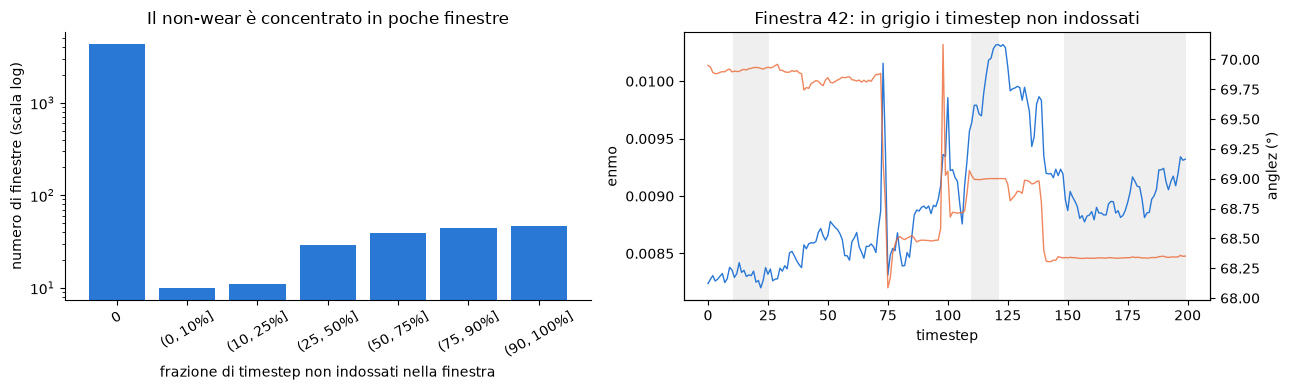

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = pd.cut(win_info['nw_frac'], bins=bins, labels=labels_bins, include_lowest=True).value_counts().reindex(labels_bins)
axes[0].bar(labels_bins, counts.values, color='#2a78d6')
axes[0].set_yscale('log')
axes[0].set_xlabel('frazione di timestep non indossati nella finestra')
axes[0].set_ylabel('numero di finestre (scala log)')
axes[0].set_title('Il non-wear è concentrato in poche finestre')
axes[0].tick_params(axis='x', rotation=30)
axes[0].spines[['top', 'right']].set_visible(False)

# una finestra con non-wear parziale: si vede il segnale "piatto" durante la rimozione del device
ex = int(win_info.index[(win_info['nw_frac'] > 0.3) & (win_info['nw_frac'] < 0.6)][0])
t = np.arange(200)
axes[1].plot(t, clean_list[ex]['enmo'].values, color='#2a78d6', linewidth=1, label='enmo')
ax2 = axes[1].twinx()
ax2.plot(t, clean_list[ex]['anglez'].values, color='#eb6834', linewidth=1, alpha=0.8, label='anglez')
ax2.set_ylabel('anglez (°)')
for s in np.where(nw_mat[ex] >= NW_STEP_THR)[0]:
    axes[1].axvspan(s - 0.5, s + 0.5, color='#999999', alpha=0.15, linewidth=0)
axes[1].set_title(f'Finestra {ex}: in grigio i timestep non indossati')
axes[1].set_xlabel('timestep')
axes[1].set_ylabel('enmo')
axes[1].spines[['top']].set_visible(False)
plt.tight_layout()
plt.show()

**Risultato:** il non-wear **non** è rumore di fondo distribuito, come sembrava dalla media per timestep. È concentrato:

- **4258 finestre su 4437 (96%) non hanno nessun timestep non indossato**; le altre 179 ne hanno quasi sempre tanti (90 finestre oltre il 75%, 46 oltre il 90%). I tratti non indossati sono lunghi (mediana ~56 step consecutivi).
- Durante il non-wear il segnale non descrive il comportamento: enmo mediano ~0 (contro 0.032 durante l'uso) e |anglez| mediano 78° contro 18°, cioè il dispositivo è appoggiato in piano e immobile (vedi l'esempio a destra).
- Il non-wear viene quasi tutto dai **241 id con una sola finestra**: lì è in media il 45% della finestra e il 63% delle finestre supera il 10%; negli id con più finestre è lo 0.3%. Questi id hanno anche più spesso la classe 1 (43% contro 33%) e batteria più bassa: è una sotto-popolazione registrata in modo diverso. Ecco perché, nella Data Understanding, il test per id su non-wear e su battery risultava significativo.

Se tenessimo queste finestre, un classificatore potrebbe imparare "finestra con il device appoggiato → classe 1": una scorciatoia legata alla qualità della registrazione, non al comportamento. E il motif più frequente rischierebbe di essere il segnale piatto del device sul tavolo.

In [42]:
def nw_policy_effect(thr):
    keep = win_info['nw_frac'] <= thr
    kept_ids = set(win_info.loc[keep, 'id'])
    lost_ids = set(win_info['id']) - kept_ids
    id_y = win_info.groupby('id')['y'].first()
    return {'soglia': thr, 'finestre tenute': int(keep.sum()), 'finestre scartate': int((~keep).sum()),
            'id tenuti': len(kept_ids), 'id persi': len(lost_ids),
            'id persi classe 0': int((id_y[list(lost_ids)] == 0).sum()),
            'id persi classe 1': int((id_y[list(lost_ids)] == 1).sum()),
            'quota classe 1 (finestre tenute)': round(win_info.loc[keep, 'y'].mean(), 3)}

print(pd.DataFrame([nw_policy_effect(t) for t in [0.0, 0.10, 0.25, 0.50, 0.90]]).to_string(index=False))

 soglia  finestre tenute  finestre scartate  id tenuti  id persi  id persi classe 0  id persi classe 1  quota classe 1 (finestre tenute)
   0.00             4258                179        326       168                 95                 73                             0.329
   0.10             4268                169        336       158                 89                 69                             0.330
   0.25             4279                158        347       147                 81                 66                             0.330
   0.50             4308                129        373       121                 66                 55                             0.330
   0.90             4391                 46        451        43                 20                 23                             0.332


**Scelta: soglia del 10%.** Una finestra con il 10% di non-wear ha al massimo 20 timestep da ricostruire; con soglie più alte dovremmo inventare per interpolazione gran parte del ciclo, che poi verrebbe letta come "riposo" dalle distanze e dagli algoritmi di motif detection. Il costo è nella tabella: si perdono ~170 finestre (meno del 4%) ma molti id, quasi tutti con una sola finestra. Lo segnaliamo come limite: i risultati a valle descrivono la popolazione con registrazioni complete.

Nelle finestre tenute, i pochi timestep non indossati vengono messi a NaN su tutti i canali comportamentali (accelerometro e luce) e interpolati linearmente.

In [43]:
BEHAV_COLS = ['X', 'Y', 'Z', 'enmo', 'anglez', 'light']

# controllo aggiuntivo: non-wear NON segnalato dal flag. Un polso indossato non resta immobile per 1/4 di ciclo:
# cerchiamo il tratto più lungo in cui anglez cambia meno di 0.5° da un timestep all'altro (dispositivo appoggiato)
def longest_still_run(anglez, tol=ANGLEZ_STILL_TOL):
    still = np.abs(np.diff(anglez)) < tol
    best = cur = 0
    for v in still:
        cur = cur + 1 if v else 0
        best = max(best, cur)
    return best

still_run = np.array([longest_still_run(d['anglez'].values) for d in clean_list])
low_nw = (win_info['nw_frac'] <= NW_WINDOW_MAX).values
hidden_nw = low_nw & (still_run >= HIDDEN_NW_STEPS)
print(f"finestre con non-wear <= {NW_WINDOW_MAX:.0%} ma anglez immobile per >= {HIDDEN_NW_STEPS} step: {hidden_nw.sum()}")
print(f"stesso controllo sulle finestre già scartate per non-wear: {((~low_nw) & (still_run >= HIDDEN_NW_STEPS)).sum()} su {(~low_nw).sum()}")

keep_mask = low_nw & ~hidden_nw
prep_list, n_imputed = [], []
for d, keep in zip(clean_list, keep_mask):
    if not keep:
        continue
    d = d.copy()
    nw_steps = d['non-wear_flag'] >= NW_STEP_THR
    d.loc[nw_steps, BEHAV_COLS] = np.nan
    d[BEHAV_COLS] = d[BEHAV_COLS].interpolate(limit_direction='both')
    n_imputed.append(int(nw_steps.sum()))
    prep_list.append(d)

n_imputed = np.array(n_imputed)
print(f"finestre tenute: {len(prep_list)}  |  scartate: {(~keep_mask).sum()} ({(~low_nw).sum()} per non-wear, {hidden_nw.sum()} per non-wear nascosto)")
print(f"finestre tenute con almeno un timestep imputato: {(n_imputed > 0).sum()}  |  timestep imputati in totale: {n_imputed.sum()}")

enmo_std = np.array([d['enmo'].std() for d in prep_list])
print(f"finestre con enmo praticamente costante (std < 1e-4): {(enmo_std < 1e-4).sum()}")

finestre con non-wear <= 10% ma anglez immobile per >= 48 step: 2
stesso controllo sulle finestre già scartate per non-wear: 157 su 169


finestre tenute: 4266  |  scartate: 171 (169 per non-wear, 2 per non-wear nascosto)
finestre tenute con almeno un timestep imputato: 9  |  timestep imputati in totale: 88
finestre con enmo praticamente costante (std < 1e-4): 0


### P3 — Selezione dei canali e trasformazione di light

Partendo dagli 8 canali dinamici:

- **battery_voltage → escluso.** Misura lo stato del dispositivo, non il comportamento. Rifacendo il test per id (vedi Data Understanding corretta) la differenza fra le classi diventa significativa (p≈0.03), ma è guidata dagli id con una sola finestra, che hanno batteria molto più bassa (~3500 mV contro ~3900) e molto più non-wear: segnala un setup di registrazione diverso, cioè un **confondente**. Tenerlo come input permetterebbe ai modelli di imparare "che tipo di registrazione è" invece del comportamento.
- **Z → escluso.** Correlazione 0.99 con anglez, che ne è una trasformazione quasi deterministica (arctan). Teniamo anglez perché è limitato in [-90, 90], interpretabile e standard negli studi di actigrafia.
- **non-wear_flag → escluso come canale.** È stato già usato come maschera in P2; dopo la pulizia vale 0 quasi ovunque e non porta altra informazione.
- **light → `log1p`** per la forte asimmetria a destra (mediana ~8 lux, coda oltre 2500).
- **X, Y → tenuti** nel set multivariato: sono quasi scorrelati da enmo e anglez e portano informazione di orientamento.

Il segnale principale per le analisi univariate (motif, clustering, KNN-DTW, shapelet) resta **enmo**, la feature con la differenza fra classi più solida anche nel test per id.

In [44]:
CHANNELS = ['enmo', 'anglez', 'light_log1p', 'X', 'Y']
STATIC_COLS = ['weekday', 'quarter', 'relative_date_PCIAT']

for d in prep_list:
    d['light_log1p'] = np.log1p(d['light'].clip(lower=0))

X_raw = np.stack([d[CHANNELS].values.T for d in prep_list]).astype(np.float32)   # (n, canali, 200)
y_all = np.array([d['sii_binary'].iloc[0] for d in prep_list])
ids_all = np.array([d['id'].iloc[0] for d in prep_list])

meta = pd.DataFrame({
    'orig_window': np.where(keep_mask)[0],
    'id': ids_all,
    'y': y_all,
    'nw_frac': win_info.loc[keep_mask, 'nw_frac'].values,
    'n_imputed': n_imputed,
    **{c: [d[c].iloc[0] for d in prep_list] for c in STATIC_COLS},
})

print(f"X_raw: {X_raw.shape}  (finestre, canali {CHANNELS}, timestep)")
print(f"finestre: {len(meta)}  |  id: {meta['id'].nunique()}")
print(f"skewness light prima/dopo log1p: {pd.Series(np.concatenate([d['light'].values for d in prep_list])).skew():.2f} -> "
      f"{pd.Series(X_raw[:, 2].ravel()).skew():.2f}")

X_raw: (4266, 5, 200)  (finestre, canali ['enmo', 'anglez', 'light_log1p', 'X', 'Y'], timestep)
finestre: 4266  |  id: 335
skewness light prima/dopo log1p: 6.74 -> 1.13


### P4 — Quanto tempo copre una finestra?

Le istruzioni parlano di medie su 30 minuti: 200 step sarebbero 100 ore contigue, quindi ~4 cicli giorno-notte. La prima versione di questa analisi partiva da questa ipotesi e, ripiegando i dati con `timestep % 48`, concludeva che le finestre fossero sfasate fra loro. Ma quel test presupponeva già ciò che doveva verificare, quindi lo sostituiamo con quattro controlli diretti:

1. **Profilo medio per timestep**, confrontato con finestre sfasate a caso. Se le finestre fossero fuori fase, il profilo medio sarebbe piatto.
2. **Autocorrelazione a lag 48 e periodogramma.** Un ciclo da 48 step produrrebbe un picco lì.
3. **Batteria come orologio del sensore.** La scarica è monotona, quindi confrontiamo il calo dentro una finestra con quello fra finestre di giorni consecutivi.
4. **Transizioni di `non-wear_flag`.** Con bin contigui da 30 minuti, un passaggio 0→1 attraverserebbe al massimo un valore parziale.

1) max/min del profilo medio: osservato 5.01  |  massimo su 200 sfasamenti casuali 1.17
   finestre con primi 40 step meno attivi degli step 80-160: 94.8%
2) autocorrelazione: {1: 0.595, 2: 0.413, 3: 0.324, 6: 0.202, 12: 0.106, 24: 0.044, 48: -0.016, 96: -0.094}
   potenza per numero di cicli nella finestra (k=1..6): [13.44  6.46  4.7   3.97  3.56  3.06] | un ciclo da 48 step cadrebbe a k~4.2
3) batteria su 3384 coppie di giorni consecutivi (mediane, mV): dentro la finestra -15.2  |  fine(k)->inizio(k+1) -0.6  |  inizio(k)->inizio(k+1) -17.0


4) tratti di valori parziali per lunghezza: {1: 3, 2: 7, 3: 504, 5: 1, 6: 97}  |  salti diretti 0<->1: 0
   valori del flag x 360: [  0.   39.   59.   61.  179.  179.1 181.  185.  296.  299.  299.7 301.
 360. ]


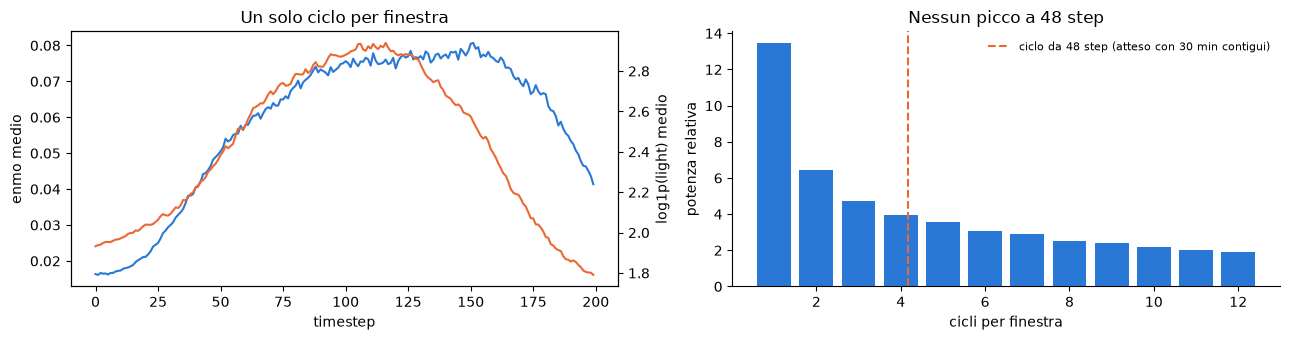

In [45]:
enmo_w = np.array([d['enmo'].values for d in raw_list], dtype=float)
light_w = np.log1p(np.array([d['light'].values for d in raw_list], dtype=float).clip(0))
nw_w = np.array([d['non-wear_flag'].values for d in raw_list], dtype=float)
bat_w = np.array([d['battery_voltage'].values for d in clean_list], dtype=float)   # senza i 4 placeholder
rd_w = np.array([d['relative_date_PCIAT'].iloc[0] for d in raw_list])
id_w = np.array([d['id'].iloc[0] for d in raw_list])
worn_w = (nw_w < NW_STEP_THR).all(axis=1)

# 1) profilo medio e modello nullo: stessa finestra, sfasata di una quantità casuale
prof = enmo_w[worn_w].mean(axis=0)
rng_p4 = np.random.default_rng(RANDOM_STATE)
null_ratio = []
for _ in range(200):
    shift = rng_p4.integers(0, 200, worn_w.sum())
    pos = (np.arange(200)[None] + shift[:, None]) % 200
    pm = np.take_along_axis(enmo_w[worn_w], pos, axis=1).mean(axis=0)
    null_ratio.append(pm.max() / pm.min())
print(f"1) max/min del profilo medio: osservato {prof.max() / prof.min():.2f}  |  massimo su 200 sfasamenti casuali {max(null_ratio):.2f}")
print(f"   finestre con primi 40 step meno attivi degli step 80-160: {(enmo_w[worn_w, :40].mean(1) < enmo_w[worn_w, 80:160].mean(1)).mean():.1%}")

# 2) autocorrelazione e periodogramma dentro la finestra
ok = enmo_w.std(axis=1) > 1e-9
Z_w = (enmo_w[ok] - enmo_w[ok].mean(1, keepdims=True)) / enmo_w[ok].std(1, keepdims=True)
acf = {l: float((Z_w[:, :-l] * Z_w[:, l:]).mean()) for l in [1, 2, 3, 6, 12, 24, 48, 96]}
power = (np.abs(np.fft.rfft(Z_w, axis=1)) ** 2).mean(axis=0)[1:]
print("2) autocorrelazione:", {k: round(v, 3) for k, v in acf.items()})
print("   potenza per numero di cicli nella finestra (k=1..6):", np.round(power[:6] / power.mean(), 2), "| un ciclo da 48 step cadrebbe a k~4.2")

# 3) batteria: calo dentro la finestra vs fra giorni consecutivi
order = np.lexsort((rd_w, id_w))
rows = [(bat_w[a, -1] - bat_w[a, 0], bat_w[b, 0] - bat_w[a, -1], bat_w[b, 0] - bat_w[a, 0])
        for a, b in zip(order, order[1:]) if id_w[a] == id_w[b] and rd_w[b] - rd_w[a] == 1]
rows = np.array(rows)
print(f"3) batteria su {len(rows)} coppie di giorni consecutivi (mediane, mV): dentro la finestra {np.median(rows[:, 0]):.1f}  |  "
      f"fine(k)->inizio(k+1) {np.median(rows[:, 1]):.1f}  |  inizio(k)->inizio(k+1) {np.median(rows[:, 2]):.1f}")

# 4) quanti valori parziali attraversa ogni transizione di non-wear
from collections import Counter
partial = Counter()
for r in nw_w:
    s = np.where(r == 0, 0, np.where(r == 1, 2, 1))
    i = 0
    while i < 200:
        if s[i] == 1:
            j = i
            while j < 200 and s[j] == 1:
                j += 1
            partial[j - i] += 1
            i = j
        else:
            i += 1
direct = sum(int((((s[:-1] == 0) & (s[1:] == 2)) | ((s[:-1] == 2) & (s[1:] == 0))).sum())
             for s in (np.where(r == 0, 0, np.where(r == 1, 2, 1)) for r in nw_w))
print(f"4) tratti di valori parziali per lunghezza: {dict(sorted(partial.items()))}  |  salti diretti 0<->1: {direct}")
print("   valori del flag x 360:", np.round(np.unique(nw_w) * 360, 1))

t = np.arange(200)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(t, prof, color='#2a78d6')
axes[0].set_xlabel('timestep'); axes[0].set_ylabel('enmo medio'); axes[0].set_title('Un solo ciclo per finestra')
ax2 = axes[0].twinx()
ax2.plot(t, light_w[worn_w].mean(axis=0), color='#eb6834'); ax2.set_ylabel('log1p(light) medio')
axes[1].bar(np.arange(1, 13), power[:12] / power.mean(), color='#2a78d6')
axes[1].axvline(200 / 48, color='#eb6834', linestyle='--', label='ciclo da 48 step (atteso con 30 min contigui)')
axes[1].set_xlabel('cicli per finestra'); axes[1].set_ylabel('potenza relativa'); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title('Nessun picco a 48 step')
axes[1].spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Risultato:** una finestra **non** si comporta come 100 ore contigue, ma come un solo ciclo giorno-notte, e le finestre sono in fase fra loro.

- **Profilo medio:** una sola gobba, con rapporto max/min 5.01 contro al massimo 1.17 con sfasamenti casuali. Nel 94.8% delle finestre i primi 40 step sono meno attivi degli step 80-160. Anche la luce ha un solo massimo, attorno al centro della finestra.
- **Periodicità:** a lag 48 l'autocorrelazione è -0.016 e il periodogramma scende regolarmente, senza picchi attorno a k≈4.2.
- **Batteria:** cala di 15.2 mV dentro una finestra e di 17.0 mV fra l'inizio di due finestre di giorni consecutivi, mentre fra la fine di una e l'inizio della successiva il salto è 0.6 mV. Una finestra dura quindi quasi quanto l'intervallo fra due finestre, cioè circa un giorno, e le finestre sono quasi contigue. Inoltre `relative_date_PCIAT` e `weekday` avanzano di 1 fra finestre consecutive.
- **Non-wear:** i valori del flag sono frazioni k/360, compatibili con medie su 360 campioni da 5 secondi, cioè i 30 minuti delle istruzioni. Ma nessuna transizione salta direttamente da 0 a 1 e di solito ne attraversa 3 parziali (circa 1/6, 1/2, 5/6): i bin da 30 minuti **si sovrappongono**, quindi gli step sono più fitti di 30 minuti.

**Come si conciliano le due cose.** L'ipotesi più coerente è una media mobile su 30 minuti campionata ogni 7-10 minuti, ma lo schema esatto non si può ricostruire dai soli dati: 200 step da 10 minuti darebbero 33 ore, non 24. **Va confermato con il docente.** Da qui in poi ragioniamo in step e parliamo di ore solo come approssimazione.

**Conseguenze per i task successivi:**

- le analisi fatte in passato con `timestep % 48` ("ciclo circadiano di 48 step", finestre sfasate, giornata riallineata sul sonno) non erano valide e sono state rimosse;
- la **distanza euclidea** ha senso, perché confronta momenti del ciclo corrispondenti;
- la DTW non serve a recuperare uno sfasamento globale, ma può tollerare piccoli anticipi e ritardi individuali;
- gli step vicini sono correlati anche per costruzione (autocorrelazione 0.595 a lag 1), perciò la PAA a 4 step perde meno di quanto sembrerebbe.

### P5 — Split train/test raggruppato per id e stratificato

Lo split viene rifatto **dopo** la pulizia (P2 ha rimosso finestre e id, quindi quello precedente non è più valido). Usiamo `StratifiedGroupKFold` come prima: nessun id può stare sia in train che in test, e la proporzione delle classi resta simile. Prendiamo il primo dei 5 fold come test (~20%).

Sul train generiamo anche 5 fold di **cross-validation** con lo stesso criterio, da usare nelle sezioni successive per scegliere gli iperparametri (k del KNN, finestra di warping della DTW, numero di cluster...) senza mai guardare il test.

In [46]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X_raw, y_all, groups=ids_all))
assert set(ids_all[train_idx]).isdisjoint(ids_all[test_idx]), "leakage: stesso id in train e test"

meta['split'] = 'train'
meta.loc[test_idx, 'split'] = 'test'

# fold di CV interni al train (per il tuning), anch'essi raggruppati per id
meta['cv_fold'] = -1
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for f, (_, va) in enumerate(cv.split(train_idx, y_all[train_idx], groups=ids_all[train_idx])):
    meta.loc[train_idx[va], 'cv_fold'] = f

summary = meta.groupby('split').agg(finestre=('y', 'size'), id=('id', 'nunique'), quota_classe_1_finestre=('y', 'mean'))
summary['quota_classe_1_id'] = meta.groupby(['split', 'id'])['y'].first().groupby('split').mean()
print(summary.round(3))
print("\nfold di CV nel train:")
print(meta[meta.split == 'train'].groupby('cv_fold').agg(finestre=('y', 'size'), id=('id', 'nunique'), quota_classe_1=('y', 'mean')).round(3))

       finestre   id  quota_classe_1_finestre  quota_classe_1_id
split                                                           
test        812   67                    0.291              0.388
train      3454  268                    0.339              0.366

fold di CV nel train:
         finestre  id  quota_classe_1
cv_fold                              
0             493  54           0.398
1             668  53           0.461
2             722  54           0.303
3             798  53           0.228
4             773  54           0.344


### P6 — Winsorizzazione di enmo

enmo ha una coda destra lunga: qualche centinaio di medie a 30 minuti supera 1 g. Non sono errori isolati (compaiono in sequenze consecutive degli stessi soggetti, quindi attività intensa reale) e non li cancelliamo. Però nelle distanze euclidee e DTW un singolo valore estremo pesa quanto decine di timestep normali. Li limitiamo (*clip*) al **percentile 99.9 calcolato sul train**.

In [47]:
ENMO_CAP = float(np.quantile(X_raw[train_idx, 0, :], 0.999))
n_capped = int((X_raw[:, 0, :] > ENMO_CAP).sum())

X_clip = X_raw.copy()
X_clip[:, 0, :] = np.minimum(X_clip[:, 0, :], ENMO_CAP)

print(f"soglia enmo (p99.9 del train): {ENMO_CAP:.3f}")
print(f"valori limitati: {n_capped} su {X_raw[:, 0, :].size} ({n_capped / X_raw[:, 0, :].size * 100:.3f}%)  |  "
      f"finestre coinvolte: {(X_raw[:, 0, :] > ENMO_CAP).any(axis=1).sum()}")

soglia enmo (p99.9 del train): 0.802
valori limitati: 1014 su 853200 (0.119%)  |  finestre coinvolte: 432


### P7 — Due normalizzazioni, per due usi diversi

Non esiste una normalizzazione "giusta" in assoluto: dipende da cosa vogliamo che la distanza confronti.

- **A — z-score globale per canale** (media e std del train, per canale, su tutte le finestre e i timestep). Mette i canali sulla stessa scala ma **conserva le differenze di livello** fra finestre: una finestra più attiva resta "più alta". È l'input naturale per ROCKET/CNN e per le distanze in cui il livello di attività conta. Visto che la differenza principale fra le classi è proprio il livello medio di enmo, questa versione è importante.
- **B — z-normalizzazione per singola serie** (ogni canale di ogni finestra a media 0 e std 1). Elimina livello e ampiezza e lascia **solo la forma**: è la normalizzazione standard per DTW, k-Shape, motif discovery, SAX e shapelet. Prezzo: si perde proprio l'informazione sul livello di attività.

Nelle sezioni successive conviene confrontare le due versioni (es. KNN-DTW su A e su B).

In [48]:
# A) z-score globale per canale, statistiche SOLO dal train
ch_mean = X_clip[train_idx].mean(axis=(0, 2))
ch_std = X_clip[train_idx].std(axis=(0, 2))
X_global = (X_clip - ch_mean[None, :, None]) / ch_std[None, :, None]

# B) z-normalizzazione per singola serie (ogni canale di ogni finestra), con protezione per serie piatte
EPS = 1e-6
s_mean = X_clip.mean(axis=2, keepdims=True)
s_std = X_clip.std(axis=2, keepdims=True)
flat = (s_std < EPS)
X_znorm = np.where(flat, 0.0, (X_clip - s_mean) / np.where(flat, 1.0, s_std)).astype(np.float32)

print("A - media/std per canale sul train:", X_global[train_idx].mean(axis=(0, 2)).round(3), X_global[train_idx].std(axis=(0, 2)).round(3))
print("A - media/std per canale sul test: ", X_global[test_idx].mean(axis=(0, 2)).round(3), X_global[test_idx].std(axis=(0, 2)).round(3))
print("B - serie (finestra, canale) piatte azzerate:", int(flat.sum()))
for w_, c_ in zip(*np.where(flat[:, :, 0])):
    print(f"    finestra {w_}, canale {CHANNELS[c_]}: valore costante {X_clip[w_, c_, 0]:.3f}")

A - media/std per canale sul train: [-0.  0. -0. -0.  0.] [1. 1. 1. 1. 1.]
A - media/std per canale sul test:  [ 0.076 -0.044  0.011  0.013  0.031] [1.117 0.975 0.978 1.    0.984]
B - serie (finestra, canale) piatte azzerate: 1
    finestra 1991, canale light_log1p: valore costante 0.405


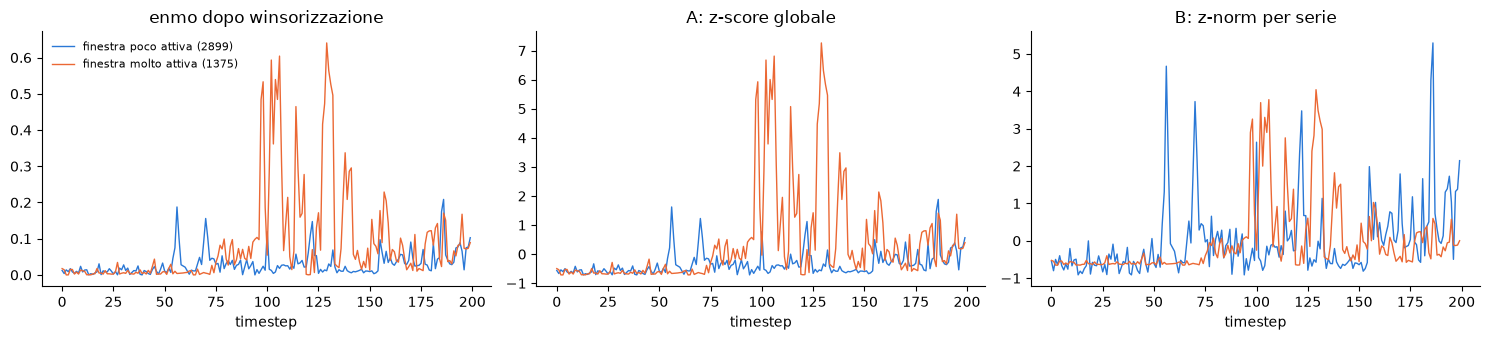

In [49]:
# confronto visivo delle due normalizzazioni su due finestre con livelli di attività diversi
w_mean = X_clip[:, 0, :].mean(axis=1)
lo_w, hi_w = int(np.argsort(w_mean)[len(w_mean) // 10]), int(np.argsort(w_mean)[-len(w_mean) // 10])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharex=True)
for ax, arr, title in zip(axes, [X_clip, X_global, X_znorm],
                          ['enmo dopo winsorizzazione', 'A: z-score globale', 'B: z-norm per serie']):
    ax.plot(arr[lo_w, 0], color='#2a78d6', linewidth=1, label=f'finestra poco attiva ({lo_w})')
    ax.plot(arr[hi_w, 0], color='#eb6834', linewidth=1, label=f'finestra molto attiva ({hi_w})')
    ax.set_title(title)
    ax.set_xlabel('timestep')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Lettura:** con A la finestra attiva resta sopra quella poco attiva (il livello è informazione); con B le due serie hanno la stessa scala e si confronta solo come l'attività è distribuita nel tempo.

### P8 — Approssimazione: PAA e SAX

La consegna suggerisce di usare un'approssimazione se il dataset è troppo grande. Qui il problema concreto è la DTW: un 1-NN con DTW sull'intero test confronta ogni finestra di test con ogni finestra di train, e la DTW ha costo quadratico nella lunghezza. Riduciamo enmo con la **PAA** (media a segmenti) e scegliamo il numero di segmenti guardando l'errore di ricostruzione.

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


 segmenti  RMSE ricostruzione (z)  varianza spiegata
      100                   0.449              0.798
       50                   0.620              0.616
       40                   0.662              0.562
       25                   0.738              0.455
       20                   0.770              0.408
       10                   0.848              0.280


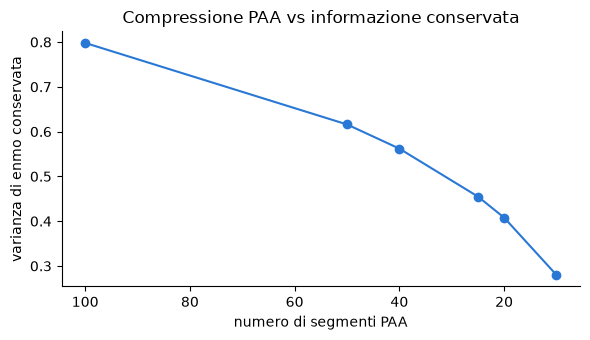

In [50]:
from tslearn.piecewise import PiecewiseAggregateApproximation, SymbolicAggregateApproximation
from tslearn.metrics import dtw
import time

enmo_z = X_znorm[:, 0, :]   # enmo z-normalizzato per serie (forma)
seg_options = [100, 50, 40, 25, 20, 10]
rows = []
for n_seg in seg_options:
    paa = PiecewiseAggregateApproximation(n_segments=n_seg)
    rec = paa.inverse_transform(paa.fit_transform(enmo_z[:, :, None]))[:, :, 0]
    rmse = np.sqrt(((rec - enmo_z) ** 2).mean())
    rows.append({'segmenti': n_seg, 'RMSE ricostruzione (z)': round(rmse, 3),
                 'varianza spiegata': round(1 - rmse ** 2, 3)})
paa_table = pd.DataFrame(rows)
print(paa_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(paa_table['segmenti'], paa_table['varianza spiegata'], marker='o', color='#2a78d6')
ax.set_xlabel('numero di segmenti PAA')
ax.set_ylabel('varianza di enmo conservata')
ax.set_title('Compressione PAA vs informazione conservata')
ax.invert_xaxis()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [51]:
N_SEG = 50   # 1 segmento = 4 timestep = ~1/50 di ciclo
paa = PiecewiseAggregateApproximation(n_segments=N_SEG)
enmo_paa_z = paa.fit_transform(enmo_z[:, :, None])[:, :, 0]                       # forma, per DTW/shapelet/clustering
enmo_paa_global = paa.fit_transform(X_global[:, 0, :, None])[:, :, 0]             # livello conservato

# costo reale della DTW: tempo per 300 coppie casuali, serie intera vs PAA
from scipy.stats import spearmanr
rng_prep = np.random.default_rng(RANDOM_STATE)
pairs = rng_prep.choice(len(enmo_z), size=(300, 2))

def time_dtw(A, **kw):
    dtw(A[0], A[1], **kw)                       # prima chiamata a vuoto: compila la funzione (numba)
    t0 = time.perf_counter()
    d = [dtw(A[i], A[j], **kw) for i, j in pairs]
    return (time.perf_counter() - t0) / len(pairs), d

band = dict(global_constraint='sakoe_chiba', sakoe_chiba_radius=12)   # warping massimo 12 step
t_full, d_full = time_dtw(enmo_z)
t_band, d_band = time_dtw(enmo_z, **band)
t_paa, d_paa = time_dtw(enmo_paa_z)
t_paa_band, d_paa_band = time_dtw(enmo_paa_z, global_constraint='sakoe_chiba', sakoe_chiba_radius=3)

n_cmp = len(train_idx) * len(test_idx)
dtw_cost = pd.DataFrame([
    ('200 step, DTW libera', t_full, 1.0),
    ('200 step, banda Sakoe-Chiba r=12', t_band, spearmanr(d_full, d_band).correlation),
    (f'PAA {N_SEG}, DTW libera', t_paa, spearmanr(d_full, d_paa).correlation),
    (f'PAA {N_SEG}, banda r=3', t_paa_band, spearmanr(d_full, d_paa_band).correlation),
], columns=['rappresentazione', 'sec_per_coppia', 'spearman_vs_DTW_intera'])
dtw_cost['ms per coppia'] = (dtw_cost['sec_per_coppia'] * 1e3).round(3)
dtw_cost['1-NN su tutto il test (min, 1 core)'] = (dtw_cost['sec_per_coppia'] * n_cmp / 60).round(1)
print(f"confronti per un 1-NN train x test: {n_cmp:,}")
print(dtw_cost.drop(columns='sec_per_coppia').round(3).to_string(index=False))

confronti per un 1-NN train x test: 2,804,648
                rappresentazione  spearman_vs_DTW_intera  ms per coppia  1-NN su tutto il test (min, 1 core)
            200 step, DTW libera                   1.000          0.832                                 38.9
200 step, banda Sakoe-Chiba r=12                   0.350          0.604                                 28.3
              PAA 50, DTW libera                   0.388          0.190                                  8.9
               PAA 50, banda r=3                   0.199          0.182                                  8.5


SAX: (4266, 50), alfabeto di 6 simboli  |  frequenza dei simboli: [0.01016409 0.3138256  0.31736521 0.15889827 0.09710267 0.10264416]


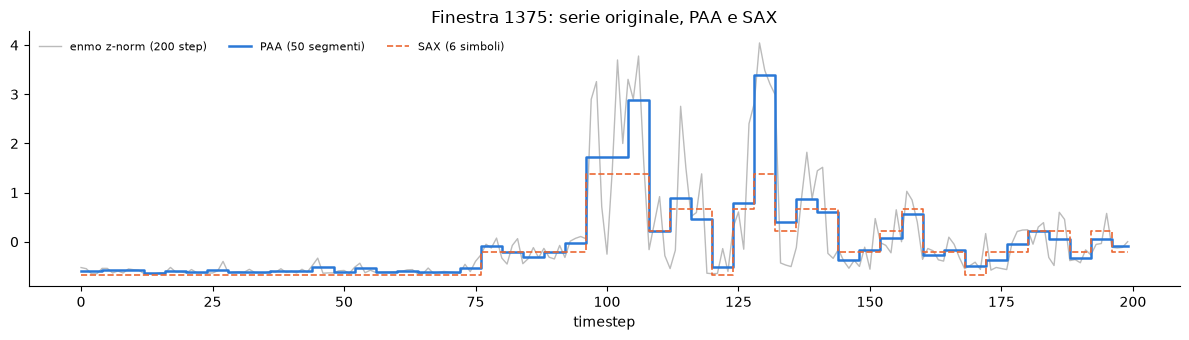

In [52]:
# SAX: discretizzazione simbolica della PAA, utile per motif (random projection) e sequential pattern mining
N_SYMBOLS = 6
sax = SymbolicAggregateApproximation(n_segments=N_SEG, alphabet_size_avg=N_SYMBOLS)
enmo_sax = sax.fit_transform(enmo_z[:, :, None])[:, :, 0].astype(int)   # simboli 0..N_SYMBOLS-1
sax_rec = sax.inverse_transform(enmo_sax[:, :, None])[:, :, 0]
print(f"SAX: {enmo_sax.shape}, alfabeto di {N_SYMBOLS} simboli  |  "
      f"frequenza dei simboli: {np.bincount(enmo_sax.ravel(), minlength=N_SYMBOLS) / enmo_sax.size}")

ex_w = hi_w
t = np.arange(200)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(t, enmo_z[ex_w], color='#bbbbbb', linewidth=1, label='enmo z-norm (200 step)')
ax.step(t, paa.inverse_transform(enmo_paa_z[ex_w][None, :, None])[0, :, 0], where='post',
        color='#2a78d6', linewidth=1.8, label=f'PAA ({N_SEG} segmenti)')
ax.step(t, sax_rec[ex_w], where='post', color='#eb6834', linewidth=1.2, linestyle='--', label=f'SAX ({N_SYMBOLS} simboli)')
ax.set_xlabel('timestep')
ax.set_title(f'Finestra {ex_w}: serie originale, PAA e SAX')
ax.legend(frameon=False, ncol=3, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Risultato:**

- **PAA a 50 segmenti** (1 segmento = 4 step, circa mezz'ora di ciclo) conserva ~62% della varianza di enmo z-normalizzato; a 100 segmenti ~80%. La parte persa è soprattutto variabilità a breve termine fra step vicini: la struttura su scala più lunga (blocchi di attività e di riposo) resta, come si vede nel grafico.
- **Costo:** con `tslearn` su un core la DTW sulla serie intera richiederebbe decine di minuti per un 1-NN su tutto il test, e la PAA-50 riduce il tempo di circa 4 volte (vedi tabella). Nella sezione di classificazione useremo l'implementazione di `aeon`, che dà gli stessi valori ed è circa 50 volte più veloce: lì il costo smette di essere un vincolo. La PAA resta utile per il clustering DTW, che ripete i confronti a ogni iterazione, e per la ricerca di shapelet.
- **Attenzione:** la PAA non è solo un'accelerazione. L'ordinamento delle distanze cambia molto (correlazione di Spearman ~0.4 con la DTW sulla serie intera), e lo stesso succede limitando il warping con una banda di Sakoe-Chiba. Su enmo, che è rumoroso a livello di singolo step, la scelta della rappresentazione cambia la geometria dei dati. Non si può decidere a priori quale sia "giusta": nella classificazione andrà scelta con la cross-validation (es. KNN-DTW su serie intera vs PAA-50, con e senza banda).
- **SAX** a 6 simboli applica la discretizzazione sulla PAA-50 della serie z-normalizzata. I simboli sono sbilanciati: il simbolo 0 è quasi assente e 1–2 coprono ~63% dei segmenti. È atteso perché enmo è asimmetrico (lunghi periodi di quiete sotto la media, brevi picchi sopra), mentre i breakpoint SAX presuppongono una gaussiana. Per il sequential pattern mining va bene; va solo tenuto presente nell'interpretazione.

### P9 — Profilo del ciclo per classe

Le finestre sono già in fase fra loro (P4), quindi non serve riallinearle: la versione precedente di questo passo, che costruiva una "giornata tipica" ruotata sul blocco meno attivo, è stata eliminata perché si basava sull'ipotesi errata di 48 step al giorno. Guardiamo invece direttamente dove le due classi differiscono lungo il ciclo: le statistiche sono per id e solo sul train, così il test resta intatto per la valutazione.

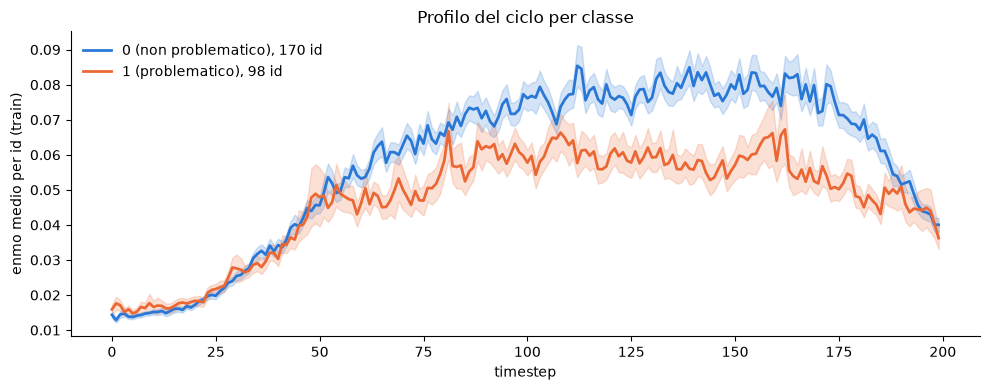

notte (step 0-40)      classe 0: 0.0201  classe 1: 0.0209  p (per id) = 5.4e-01
giorno (step 60-180)   classe 0: 0.0740  classe 1: 0.0568  p (per id) = 5.1e-07


In [53]:
NIGHT, DAY = (0, 40), (60, 180)   # fasi del ciclo lette dal profilo medio di P4

tr_df = pd.DataFrame(X_clip[train_idx, 0, :])
tr_df['id'] = ids_all[train_idx]
by_id = tr_df.groupby('id').mean()
y_by_id = pd.Series(y_all[train_idx], index=ids_all[train_idx]).groupby(level=0).first()

fig, ax = plt.subplots(figsize=(10, 4))
for cls, color, name in zip([0, 1], ['#2a78d6', '#eb6834'], ['0 (non problematico)', '1 (problematico)']):
    g = by_id[y_by_id == cls].values
    m_, se = g.mean(axis=0), g.std(axis=0) / np.sqrt(len(g))
    ax.plot(m_, color=color, linewidth=2, label=f'{name}, {len(g)} id')
    ax.fill_between(np.arange(200), m_ - se, m_ + se, color=color, alpha=0.2)
ax.set_xlabel('timestep'); ax.set_ylabel('enmo medio per id (train)')
ax.set_title('Profilo del ciclo per classe')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

for name, (a, b) in {'notte (step 0-40)': NIGHT, 'giorno (step 60-180)': DAY}.items():
    v = by_id.iloc[:, a:b].mean(axis=1)
    p = stats.ttest_ind(v[y_by_id == 0], v[y_by_id == 1], equal_var=False).pvalue
    print(f"{name:<22} classe 0: {v[y_by_id == 0].mean():.4f}  classe 1: {v[y_by_id == 1].mean():.4f}  p (per id) = {p:.1e}")

**Risultato (train, per id):** le classi differiscono **di giorno** (0.0740 contro 0.0568, p≈5e-7) ma non di notte (0.0201 contro 0.0209, p=0.54). La forma del ciclo è simile e la classe problematica è soprattutto meno attiva durante le ore di veglia. Le fasi notte e giorno sono definite leggendo il profilo medio, quindi sono descrittive e dipendono dall'interpretazione di P4. Nessun modello le usa come input.

### P10 — Riepilogo e salvataggio

Salviamo tutte le rappresentazioni nello stesso file, insieme agli indici di train/test, ai fold di CV, ai parametri della pipeline e alle statistiche del train (per applicare la stessa trasformazione a dati nuovi). La tabella riassume quale rappresentazione usare per quale task.

In [54]:
representations = pd.DataFrame([
    ('X_raw',                 X_raw.shape,                'canali puliti, unità originali (light in log1p)', 'EDA, feature engineering'),
    ('X_global',              X_global.shape,             'z-score globale per canale (train), enmo winsorizzato', 'ROCKET/MiniRocket, CNN, KNN "di livello"'),
    ('X_znorm',               X_znorm.shape,              'z-norm per singola serie, enmo winsorizzato', 'KNN-DTW (serie intera), shapelet, motif'),
    ('enmo_paa_z',            enmo_paa_z.shape,           f'enmo z-norm, PAA {N_SEG} segmenti', 'clustering DTW/k-Shape, ricerca shapelet (veloce)'),
    ('enmo_paa_global',       enmo_paa_global.shape,      f'enmo z-score globale, PAA {N_SEG} segmenti', 'KNN/clustering euclidei che conservano livello e fase, PCA/t-SNE'),
    ('enmo_sax',              enmo_sax.shape,             f'SAX, {N_SYMBOLS} simboli', 'motif (random projection), sequential pattern mining'),
], columns=['nome', 'shape', 'contenuto', 'uso consigliato'])
print(representations.to_string(index=False))

prepared = {
    'X_raw': X_raw, 'X_global': X_global, 'X_znorm': X_znorm,
    'enmo_paa_z': enmo_paa_z, 'enmo_paa_global': enmo_paa_global, 'enmo_sax': enmo_sax,
    'y': y_all, 'ids': ids_all, 'meta': meta,
    'train_idx': train_idx, 'test_idx': test_idx,
    'channels': CHANNELS, 'static_cols': STATIC_COLS,
    'scaling': {'channel_mean': ch_mean, 'channel_std': ch_std, 'enmo_cap': ENMO_CAP},
    'params': {'XYZ_GLITCH_THR': XYZ_GLITCH_THR, 'BATTERY_GLITCH_THR': BATTERY_GLITCH_THR,
               'NW_STEP_THR': NW_STEP_THR, 'NW_WINDOW_MAX': NW_WINDOW_MAX, 'N_SEG': N_SEG,
               'N_SYMBOLS': N_SYMBOLS, 'RANDOM_STATE': RANDOM_STATE},
}
with open('CMI_timeseries_prepared.pkl', 'wb') as f:
    pickle.dump(prepared, f)
print("\nsalvato in CMI_timeseries_prepared.pkl")

           nome          shape                                             contenuto                                                  uso consigliato
          X_raw (4266, 5, 200)       canali puliti, unità originali (light in log1p)                                         EDA, feature engineering
       X_global (4266, 5, 200) z-score globale per canale (train), enmo winsorizzato                         ROCKET/MiniRocket, CNN, KNN "di livello"
        X_znorm (4266, 5, 200)           z-norm per singola serie, enmo winsorizzato                          KNN-DTW (serie intera), shapelet, motif
     enmo_paa_z     (4266, 50)                          enmo z-norm, PAA 50 segmenti                clustering DTW/k-Shape, ricerca shapelet (veloce)
enmo_paa_global     (4266, 50)                 enmo z-score globale, PAA 50 segmenti KNN/clustering euclidei che conservano livello e fase, PCA/t-SNE
       enmo_sax     (4266, 50)                                        SAX, 6 simboli             mot

**Come ricaricare il dataset preparato nelle sezioni successive:**

```python
with open('CMI_timeseries_prepared.pkl', 'rb') as f:
    PREP = pickle.load(f)
tr, te = PREP['train_idx'], PREP['test_idx']
Xtr, Xte = PREP['enmo_paa_z'][tr], PREP['enmo_paa_z'][te]
ytr, yte = PREP['y'][tr], PREP['y'][te]
cv_folds = PREP['meta'].loc[tr, 'cv_fold'].values   # per GridSearchCV con PredefinedSplit
```

### Riepilogo della data preparation

| | prima | dopo |
|---|---|---|
| finestre | 4437 | 4266 |
| id | 494 | 335 |
| quota classe 1 (finestre) | 33.4% | 33.0% |
| canali dinamici | 8 | 5 (enmo, anglez, light_log1p, X, Y) |
| timestep con glitch del sensore | 9 (+4 battery) | 0 (interpolati) |
| finestre con non-wear | 179 | 9 (88 timestep interpolati in totale) |
| split | — | train 3454 finestre / 268 id, test 812 / 67 id, nessun id condiviso |

Limite da dichiarare nella relazione: lo scarto delle finestre con non-wear elimina soprattutto gli id con una sola finestra. Il dataset preparato rappresenta i soggetti con registrazioni complete e per più giorni, non l'intera popolazione originale.